# CLEVR questions with named variables: perfect sight (E3)

**The task.** The same as in `e0_perfect_sight.ipynb`, which introduces the dataset: each CLEVR question comes with a **functional program**, and a small compiler turns the program into an sLTN formula that ties the answer to the objects of the scene. The goal of the CLEVR experiments is to learn the objects' attributes (colour, size, material, shape) from the answers alone. Here, as in E0, nothing is learned yet: the attributes are read from the scene file (**perfect sight**), so a correct formula must give the dataset's answer on every question.

**What changes from E0: how a batch of questions is written.** A batch holds many questions of one **family** (one program skeleton, so one formula), each with its own scene and its own values.

- **E0** gives every question a position on a structural axis `Question`, with structural variable `q`. Everything that belongs to a question is indexed by it: the scene is `x[q, o]`, the first colour the question names is `c0[q]`, and the relations are tensors `R0(q, o, o1)` grounded from the scene graph, one per `relate` of the program.
- **E3 (here)** writes each question as **one individual** of ordinary variables: the scene `x`, the values the question names (`c0`, `s0`, `r0`, ...) and the answer. A family's rule quantifies them **together**, `forall (x, c0, s0, r0, ...): ...`, so question i's scene only ever meets question i's values. There is no `Question` axis and no `[q]`. Each object's features (presence, 3D position and attributes) sit in one vector `x[o]`, and a single predicate `R(x[o], x[o1], r)` computes the relation from the positions.

**The model in words.** For example, family 75 is the template *"what color is the ⟨filter 2⟩ object that is ⟨direction⟩ of the ⟨filter 1⟩ object?"*. One of its questions is *"What color is the matte thing in front of the large cube?"* (answer: cyan). Its formula reads almost like the question: there is an object `o1` that is large and a cube, and an object `o2` in front of it that is matte, and `o2` has the answer's colour. The values (large, cube, front, matte) are the question's variables `z0, s0, r0, m1`, and the answer is the variable `ans_c`.

**Why it is done this way:**
- **Readability.** Predicates are named by their meaning (`C(x[o], c0)`: "o has colour c0") and the formulas carry no question index.
- **One place for an object's features.** Presence, position and attributes are all in `x[o]`. A predicate reads the part it needs, so the relations are computed like the attributes, instead of being given as separate tensors.
- **Perfect sight first.** Before any learning, the new formulas must agree with E0's, question by question.

**What this example shows:**
- **Diagonal quantification to pair the data of one example.** `forall (x, c0, ...)` takes the i-th value of every variable together. It plays the role of E0's `Question` axis, written with ordinary variables.
- **Guards for padding, read from the data.** Scenes have 3 to 10 objects, padded to 10. A presence bit in `x[o]` and the guard `exists o | Present(x[o]): ...` keep the empty positions out of every object quantifier.
- **A relation computed from features.** `R(x[o], x[o1], r)` reads the two objects' positions, so the relation is a predicate like the attributes, not a structural relation given as a tensor.
- **A variable of sort `Bool` as a formula.** A yes/no question's answer is a variable `yes`, used directly in `yes <-> ...`.
- **One formula per family, chosen by the batch.** A batch only holds questions of one family, so no formula needs a guard to say which template it is about.
- **Reading the value of each example.** sLTN returns only the aggregate of a quantifier; Section 5 shows how to read the truth value of each question inside the diagonal `forall`.

**Compute.** CPU, about a minute in all.

**Data.** [CLEVR](https://cs.stanford.edu/people/jcjohns/clevr/) (Johnson et al., CVPR 2017), licensed CC BY 4.0. The first run downloads the scene and question files (85 MB) into `notebooks/datasets/`. The 12 validation images shown are included in `images/`.

In [1]:
import collections
import inspect
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import torch

sys.path.insert(0, str(Path.cwd().resolve()))          # notebooks/examples/CLEVR
import clevr_diag as cd
from clevr_sltn import DATA, IMAGES, load, sltn_version

print("sltn:", sltn_version())
t0 = time.perf_counter()
scenes, questions = load(DATA, "val")                  # downloads the files the first time
qs = [q for q in questions if cd.in_scope(q)]
print(f"{len(scenes)} scenes, {len(questions)} questions, {len(qs)} in scope (no counting); "
      f"loaded in {time.perf_counter() - t0:.0f}s")

sltn: {'commit': '5c2bb0f85a12db17d337294455f21c8163b94fcb', 'branch': 'bug-fixes-temp', 'dirty': True}


15000 scenes, 149991 questions, 101028 in scope (no counting); loaded in 3s


## 1. A question is one individual

Every variable of a batch has **one value per question**, in the same order:

| Variable | Sort | Value for one question |
|---|---|---|
| `x` | `Object`, with structural dimension `Obj` (10 positions) | the scene: one row `x[o]` per object position |
| `c<k>`, `z<k>`, `m<k>`, `s<k>` | `Col` (8), `Siz` (2), `Mat` (2), `Shp` (3) | the colour, size, material and shape that filter `k` of the program names: one-hot, or all ones if the filter doesn't name that attribute |
| `r<k>` | `Dir` (4) | the direction of the `k`-th `relate`: one-hot over left, right, front, behind |
| `yes` | `Bool` | the answer of a yes/no question: 1 or 0 |
| `ans_c`, `ans_z`, `ans_m`, `ans_s` | `Col`, ... | the answer of a "what colour / size / ..." question, one-hot |

A **filter** is a run of `filter_<attr>(value)` steps in the program, such as "large cube" (size large, shape cube); filters are numbered in the order the program meets them. An all-ones value makes its atom exactly true, so "the large cube" accepts any colour and any material. The numbering of filters and relates comes from E0's `canonical` (Section 3 of E0), unchanged.

**The rule quantifies them together.** `forall (x, c0, ..., ans_c): φ` is a **diagonal** quantifier: sLTN pairs the i-th value of each variable, so φ is evaluated once per question, on that question's scene and values, and the results are aggregated (pMeanError, p = 2, as in E0).

**The object features.** `x[o]` is a vector of 19 numbers: a presence bit, the 3D position from the scene file, then the four attributes one-hot (perfect sight). Positions past the scene's last object are all zeros, so their presence bit is 0.

x[o] layout: present 0 | xyz slice(1, 4, None) | {'color': slice(4, 12, None), 'size': slice(12, 14, None), 'material': slice(14, 16, None), 'shape': slice(16, 19, None)} | total 19


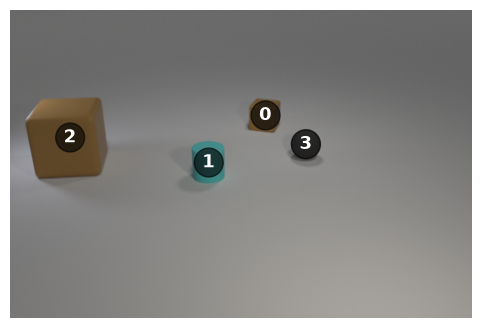

x[0]: present 1, xyz [-1.29, 1.94, 0.35], brown small rubber cube
x[1]: present 1, xyz [0.01, -0.94, 0.35], cyan small rubber cylinder
x[2]: present 1, xyz [-2.45, -2.94, 0.7], brown large rubber cube
x[3]: present 1, xyz [0.72, 1.36, 0.35], gray small rubber sphere
x[4]: present 0 (empty position)
x[5]: present 0 (empty position)
x[6]: present 0 (empty position)
x[7]: present 0 (empty position)
x[8]: present 0 (empty position)
x[9]: present 0 (empty position)


In [2]:
print("x[o] layout: present", cd.PRESENT, "| xyz", cd.XYZ, "|", {a: cd.OFFSET[a] for a in cd.ATTRS}, "| total", cd.FEAT)
q_run = next(q for q in qs if q["question"] == "What color is the matte thing in front of the large cube?")
s_run = scenes[q_run["image_index"]]
x_run = cd.scene_rows(s_run)
fig, ax = plt.subplots(figsize=(6, 4))
ax.imshow(plt.imread(IMAGES / s_run["image_filename"]))
for i, ob in enumerate(s_run["objects"]):
    px, py, _ = ob["pixel_coords"]
    ax.text(px, py, str(i), color="white", fontsize=13, weight="bold", ha="center", va="center",
            bbox=dict(boxstyle="circle", fc="black", alpha=0.6))
ax.axis("off")
plt.show()
for o in range(cd.O):
    row = x_run[o]
    if row[cd.PRESENT] == 0:
        print(f"x[{o}]: present 0 (empty position)")
        continue
    attrs = " ".join(cd.VALUES[a][int(row[cd.OFFSET[a]].argmax())] for a in cd.ATTRS)
    print(f"x[{o}]: present 1, xyz {[round(v, 2) for v in row[cd.XYZ].tolist()]}, {attrs}")

## 2. Relations from the positions

CLEVR defines the four directions from the camera: each scene file gives a unit vector for left, right, front and behind, and the same camera is used in every scene. Object `o1` is in direction `d` of object `o` when the step from `o` to `o1` points along `d`:

`R(x[o], x[o1], r)` = 1 iff (xyz(o1) − xyz(o)) · d > 0, where `d` is the direction that `r` picks.

Before using it, we check that this rule gives exactly CLEVR's relations (the `relationships` lists of the scene file), for every ordered pair of objects in every validation scene.

In [3]:
D = cd.camera_directions(scenes)                       # [4, 3]; asserts the camera is the same in every scene
print("directions:", {d: [round(v, 3) for v in D[i].tolist()] for i, d in enumerate(cd.DIRS)})
wrong = total = 0
for s in scenes:
    xyz = torch.tensor([ob["3d_coords"] for ob in s["objects"]])
    for i, d in enumerate(cd.DIRS):
        computed = ((xyz[None, :, :] - xyz[:, None, :]) @ D[i] > 0)    # [o, o1]: o1 is d of o
        given = torch.zeros_like(computed)
        for u, objs in enumerate(s["relationships"][d]):
            given[u, objs] = True
        wrong += (computed != given).sum().item()
        total += computed.numel()
print(f"{wrong} of {total} (object, object, direction) triples differ from the scene file")

directions: {'left': [-0.656, -0.754, 0.0], 'right': [0.656, 0.754, -0.0], 'front': [0.754, -0.656, -0.0], 'behind': [-0.754, 0.656, 0.0]}


0 of 2844328 (object, object, direction) triples differ from the scene file


## 3. From a program to a formula

`cd.compile_question` writes a family's formula from a question's program. It walks the program like E0's compiler (one method per kind of step), with three differences in what it writes:

| Step | E0 writes | E3 writes |
|---|---|---|
| a filter `k` on object `v` | `IsC(color(x[q, v]), ck[q]) & ...` | `C(x[v], ck) & Z(x[v], zk) & M(x[v], mk) & S(x[v], sk)` |
| an object of the scene | `Present(q, v)` inside the body | the guard of its quantifier: `exists v | Present(x[v]): ...` |
| `relate` number `k` | `Rk(q, o1, v)`, a tensor per relate | `R(x[o1], x[v], rk)`, one predicate |
| `same_color` | `IsC(color(x[q, o1]), color(x[q, v]))` | `SameC(x[o1], x[v])` |

It returns two formulas per family:
- **the rule**, the knowledge that training will make true: for a "what colour" question, *the object the question picks has the answer's colour*, `... & C(x[o2], ans_c)`; for a yes/no question, `yes <-> body`;
- **the reply**, the same body with the answer left open: a free variable `kc` over the 8 colours gives one truth value per colour, and the highest is the formula's reply. For a yes/no question the reply is the body itself.

The running question, with its skeleton and its parameters:

In [4]:
def pretty(f):
    # one line per nested quantifier, indented by depth
    out, depth, i = [], 0, 0
    line = ""
    while i < len(f):
        if f.startswith("(exists", i) and line.strip():
            out.append(line)
            line = "  " * depth
        ch = f[i]
        depth += ch == "("
        depth -= ch == ")"
        line += ch
        i += 1
    return "\n".join(out + [line])

key, fil, rels = cd.canonical(q_run)
print(q_run["question"], "->", q_run["answer"])
print("skeleton:  ", key)
print("filters:   ", fil)
print("directions:", rels)
c_run = cd.compile_question(q_run)
print("\nrule:\n" + pretty(c_run.rule))
print("\nreply:\n" + pretty(c_run.predict))

What color is the matte thing in front of the large cube? -> cyan
skeleton:   query_color(unique(F(relate(unique(F(scene()))))))
filters:    [{'shape': 'cube', 'size': 'large'}, {'material': 'rubber'}]
directions: ['front']

rule:
forall (x, c0, z0, m0, s0, c1, z1, m1, s1, r0, ans_c): 
(exists o2 | Present(x[o2]): ((
      (exists o1 | Present(x[o1]): ((C(x[o1], c0) & Z(x[o1], z0) & M(x[o1], m0) & S(x[o1], s0)) & R(x[o1], x[o2], r0))) & C(x[o2], c1) & Z(x[o2], z1) & M(x[o2], m1) & S(x[o2], s1)) & C(x[o2], ans_c)))

reply:
forall (x, c0, z0, m0, s0, c1, z1, m1, s1, r0): 
(exists o2 | Present(x[o2]): ((
      (exists o1 | Present(x[o1]): ((C(x[o1], c0) & Z(x[o1], z0) & M(x[o1], m0) & S(x[o1], s0)) & R(x[o1], x[o2], r0))) & C(x[o2], c1) & Z(x[o2], z1) & M(x[o2], m1) & S(x[o2], s1)) & C(x[o2], kc)))


`o1` is the large cube (filter 0), `o2` the matte thing in front of it (filter 1, relate 0). Filter 0 names no colour and no material, so `c0` and `m0` are all ones for this question; filter 1 names only the material. Another question of family 75, with different values, has the same skeleton and so the same formula:

In [5]:
q_ball = next(q for q in qs if q["question"] == "There is a small ball left of the gray metallic sphere; what color is it?")
print(q_ball["question"], "->", q_ball["answer"])
print("filters:   ", cd.canonical(q_ball)[1], "| directions:", cd.canonical(q_ball)[2])
print("same rule as the running question:", cd.compile_question(q_ball).rule == c_run.rule)

There is a small ball left of the gray metallic sphere; what color is it? -> brown
filters:    [{'shape': 'sphere', 'material': 'metal', 'color': 'gray'}, {'shape': 'sphere', 'size': 'small'}] | directions: ['left']
same rule as the running question: True


A yes/no question: its answer is the `Bool` variable `yes`, used directly as a formula. `same_shape` brings in `Neq(o1, o2)`, a structural relation over pairs of positions ("another object"), and `SameS`.

In [6]:
q_yn = next(q for q in qs if q["program"][-1]["function"] == "exist"
            and any(n["function"] == "same_shape" for n in q["program"]))
print(q_yn["question"], "->", q_yn["answer"])
print("filters:", cd.canonical(q_yn)[1])
print("\nrule:\n" + pretty(cd.compile_question(q_yn).rule))

Are there any other things that are the same shape as the big metallic object? -> no
filters: [{'material': 'metal', 'size': 'large'}, {}]

rule:
forall (x, c0, z0, m0, s0, c1, z1, m1, s1, yes): (yes <-> 
  (exists o2 | Present(x[o2]): (
      (exists o1 | Present(x[o1]): ((C(x[o1], c0) & Z(x[o1], z0) & M(x[o1], m0) & S(x[o1], s0)) & Neq(o1, o2) & SameS(x[o1], x[o2]))) & C(x[o2], c1) & Z(x[o2], z1) & M(x[o2], m1) & S(x[o2], s1))))


How many formulas? Grouping the in-scope questions by skeleton gives the families, and each batch below holds the questions of one family. Since the batch decides which formula is evaluated, no formula needs a condition saying which template a question comes from.

In [7]:
families = collections.defaultdict(list)
for q in qs:
    families[cd.canonical(q)[0]].append(q)
print(f"{len(families)} formulas for {len(qs)} questions "
      f"({len({q['question_family_index'] for q in qs})} CLEVR templates)")

56 formulas for 101028 questions (60 CLEVR templates)


## 4. The signature and the perfect-sight interpretation

The signature declares the variables of Section 1 (up to 12 filters and 6 relates, so `c0` ... `c11` and `r0` ... `r5`), the predicates, the structural dimension `Obj` with its variables `o1` ... `o12`, and the structural relation `Neq`. In the interpretation, every predicate reads its slice of `x`:

In [8]:
print(inspect.getsource(cd.make_interp))
sig = cd.make_signature()
it = cd.make_interp(sig, D)

def make_interp(sig, directions, logic=None):
    """Perfect sight: every predicate reads x. `directions` is camera_directions(scenes)."""
    if logic is None:
        logic = Logic().with_defaults()
        logic["exists,Obj"] = AggregMax()
        logic["forall"] = AggregPMeanError(p=2)
    it = Interpretation(sig, logic=logic)
    it["Obj"] = range(O)
    it["Object"] = sltn.Type("Object", shape=(FEAT,))
    it["Dir"] = sltn.Type("Dir", shape=(len(DIRS),))
    it["Neq"] = 1 - torch.eye(O)
    it["Present"] = lambda x: x[..., PRESENT:PRESENT + 1]
    # o1 is in direction d of o iff (o1 - o) points along d: exact on CLEVR (checked in the notebook)
    it["R"] = lambda x, x1, r: (((x1[..., XYZ] - x[..., XYZ]) @ directions.T > 0).float() * r).sum(-1, keepdim=True)
    for a in ATTRS:
        n = len(VALUES[a])
        it[SORT[a]] = sltn.Type(SORT[a], shape=(n,))
        it[PRED[a]] = (lambda s: lambda x, v: (x[..., s] * v).sum(-1, keepdim=True))(OFFSET[a])
        it[SAME[a]] = (lambda

**The logic** is E0's: the default operators, `max` for ∃ over the objects (exact on true/false values), and pMeanError (p = 2) for the ∀ over the questions, here the diagonal ∀.

A batch is grounded with `cd.family_batch`: one tensor per variable, one row per question. For the running question and the other question of family 75:

In [9]:
batch = cd.family_batch([q_run, q_ball], {s["image_index"]: cd.scene_rows(s) for s in
                                          (scenes[q_run["image_index"]], scenes[q_ball["image_index"]])})
for name in c_run.variables + ["ans_c"]:
    v = batch[name]
    print(f"{name:6s} {str(list(v.shape)):12s}", "" if name == "x" else v.tolist())
cd.ground(it, batch)

x      [2, 10, 19]  
c0     [2, 8]       [[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0], [1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]]
z0     [2, 2]       [[0.0, 1.0], [1.0, 1.0]]
m0     [2, 2]       [[1.0, 1.0], [0.0, 1.0]]
s0     [2, 3]       [[1.0, 0.0, 0.0], [0.0, 1.0, 0.0]]
c1     [2, 8]       [[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0], [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]]
z1     [2, 2]       [[1.0, 1.0], [1.0, 0.0]]
m1     [2, 2]       [[1.0, 0.0], [1.0, 1.0]]
s1     [2, 3]       [[1.0, 1.0, 1.0], [0.0, 1.0, 0.0]]
r0     [2, 4]       [[0.0, 0.0, 1.0, 0.0], [1.0, 0.0, 0.0, 0.0]]
ans_c  [2, 8]       [[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0], [0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0]]


## 5. The truth value of each question

Evaluating the rule gives **one** number, its truth value over the batch: the diagonal ∀ has already aggregated the questions.

In [10]:
print("rule over the 2 questions:", round(it(sig.parse(c_run.rule)).value.item(), 4))

rule over the 2 questions: 0.999


To score a model, though, we need each question's reply: the body's truth value for question i alone. In E0 it was free: the body, evaluated without its ∀, still had the `Question` axis. Here that doesn't work. Without the `forall (x, c0, ...)` the variables are no longer paired, and the body would be evaluated on every combination of one question's scene with another question's values.

So the values are read **inside** the quantifier. `cd.per_question` evaluates the reply formula with a ∀ aggregator that keeps a copy of what it aggregates (one value per question) and then aggregates as usual. It uses only the public `Logic` interface, but it is a workaround: sLTN has no direct way to ask for the per-example values of a diagonal quantifier.

In [11]:
v = cd.per_question(it, sig.parse(c_run.predict))      # [2 questions, 8 colours]
for q, row in zip([q_run, q_ball], v):
    best = cd.VALUES["color"][int(row.argmax())]
    print(f"{q['question'][:60]:60s} reply {best:7s} answer {q['answer']:7s}",
          {c: round(t, 3) for c, t in zip(cd.VALUES["color"], row.tolist()) if t > 1e-3})

What color is the matte thing in front of the large cube?    reply cyan    answer cyan    {'cyan': 1.0}
There is a small ball left of the gray metallic sphere; what reply brown   answer brown   {'brown': 1.0}


## 6. All the validation questions

Every in-scope question, one batch per family. A yes/no reply is "yes" when the truth value is above 0.5; a query's reply is the value with the highest truth value. We also report each family's rule, which must be close to 1 when the formulas are right.

In [12]:
scene_x = {s["image_index"]: cd.scene_rows(s) for s in scenes}
t0 = time.perf_counter()
rows = []
for key, group in sorted(families.items(), key=lambda kv: -len(kv[1])):
    c = cd.compile_question(group[0])
    g = cd.family_batch(group, scene_x)
    cd.ground(it, g)
    v = cd.per_question(it, sig.parse(c.predict))
    if c.kind == "yesno":
        ok = (v > 0.5) == (g["yes"].squeeze(-1) > 0.5)
    else:
        ok = v.argmax(-1) == g[cd.ANS[c.kind]].argmax(-1)
    with torch.no_grad():
        sat = it(sig.parse(c.rule)).value.item()
    kind = "query" if c.kind != "yesno" else "compare" if key.startswith("equal_") else "exist"
    rows.append(dict(key=key, kind=kind, n=len(group), correct=int(ok.sum()), sat=sat))
n = sum(r["n"] for r in rows)
print(f"{len(rows)} formulas, {n} questions: {sum(r['correct'] for r in rows)} replies equal the dataset's answer "
      f"({time.perf_counter() - t0:.0f}s)")
for kind in ("exist", "compare", "query"):
    rs = [r for r in rows if r["kind"] == kind]
    print(f"  {kind:8s} {sum(r['n'] for r in rs):6d} questions, {sum(r['correct'] for r in rs):6d} correct")
print(f"rule truth values: min {min(r['sat'] for r in rows):.4f}, max {max(r['sat'] for r in rows):.4f}")

56 formulas, 101028 questions: 101028 replies equal the dataset's answer (10s)
  exist     20196 questions,  20196 correct
  compare   27098 questions,  27098 correct
  query     53734 questions,  53734 correct
rule truth values: min 0.9990, max 0.9990


The rules come out at 0.999, not 1, because the default operators are the stable ones, which keep every truth value a little away from 0 and 1.

## 7. The same truth values as E0

Agreeing on the answers is the main check. A stronger one: the E3 reply and E0's formula should give the same truth value for every question, since they are meant to be the same formula written differently. We compare them on 300 questions per family, with E0's compiler and interpretation.

In [13]:
import clevr_sltn as e0
from e0_perfect_sight import make_interp as e0_interp, ground as e0_ground, values as e0_values

e0_sig = e0.make_signature()
e0_it = e0_interp(e0_sig)
e0_cache = {s["image_index"]: e0.scene_tensors(s) for s in scenes}
worst, m = 0.0, 0
for key, group in families.items():
    group = group[:300]
    c0_, c3 = e0.compile_question(group[0]), cd.compile_question(group[0])
    e0_ground(e0_it, e0.batch_tensors(group, e0_cache, c0_.n_slots, c0_.n_rels), c0_.n_slots, c0_.n_rels)
    with torch.no_grad():
        r = e0_it(e0_sig.parse(c0_.body))
    v0 = e0_values(r, ["q"]) if c0_.kind == "yesno" else e0_values(r, ["q", e0.KVAR[c0_.kind]])
    cd.ground(it, cd.family_batch(group, scene_x))
    v3 = cd.per_question(it, sig.parse(c3.predict))
    worst, m = max(worst, (v0 - v3).abs().max().item()), m + len(group)
print(f"{m} questions: largest difference between the E0 and E3 truth values {worst:.1e}")

16800 questions: largest difference between the E0 and E3 truth values 4.0e-06


## Findings

- **The new formulas are right.** With perfect sight, every in-scope validation question (101,028, across 56 formulas) gets the dataset's answer, and every rule is at 0.999.
- **They are E0's formulas, written differently.** On 16,800 questions, the E3 and E0 truth values differ by at most a few millionths, the size of the stable operators' epsilon.
- **The relations follow from the positions, exactly.** On every ordered pair of objects in every validation scene, the rule of Section 2 gives CLEVR's relations with no exception. So the relations can live in `x` with the other features, and a learned relation would read the same positions.
- **Reading per-question values needs a workaround.** A diagonal quantifier returns only its aggregate. For training that is all we need (the loss is the rules' truth value); for scoring, Section 5 records the values inside the ∀.

**Next.** Learning the attributes from the answers with these formulas: the networks replace `C`, `Z`, `M` and `S`, reading an object's crop instead of the one-hot slice of `x`.